<a href="https://colab.research.google.com/github/0Francis/CouseraDSCourse/blob/main/CS5_MD5_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import yfinance as yf
import pandas as pd
from bs4 import BeautifulSoup
import requests
import warnings
warnings.filterwarnings('ignore', category=FutureWarning)
import matplotlib.pyplot as plt




In [ ]:
def make_graph(stock_data, revenue_data, stock):
  stock_data_specific = stock_data[stock_data.Date <= '2021--06-14']
  revenue_data_specific = revenue_data[revenue_data.Date <= '2021-04-30']

  fig, axes = plt.subplots(2,1,figsize=(12,8),sharex=True)
      # Stock price
  axes[0].plot(pd.to_datetime(stock_data_specific.Date), stock_data_specific.Close.astype("float"), label="Share Price", color="blue")
  axes[0].set_ylabel("Price ($US)")
  axes[0].set_title(f"{stock} - Historical Share Price")

    # Revenue
  axes[1].plot(pd.to_datetime(revenue_data_specific.Date), revenue_data_specific.Revenue.astype("float"), label="Revenue", color="green")
  axes[1].set_ylabel("Revenue ($US Millions)")
  axes[1].set_xlabel("Date")
  axes[1].set_title(f"{stock} - Historical Revenue")

  plt.tight_layout()
  plt.show()




In [ ]:
tsla = yf.Ticker("TSLA")
tlsa_data = tsla.history(period="max")
tlsa_data.reset_index(inplace=True)
tlsa_data.head()


,Date,Open,High,Low,Close,Volume,Dividends,Stock Splits
0,2010-06-29 00:00:00-04:00,1.266667,1.666667,1.169333,1.592667,281494500,0.0,0.0
1,2010-06-30 00:00:00-04:00,1.719333,2.028000,1.553333,1.588667,257806500,0.0,0.0
2,2010-07-01 00:00:00-04:00,1.666667,1.728000,1.351333,1.464000,123282000,0.0,0.0
3,2010-07-02 00:00:00-04:00,1.533333,1.540000,1.247333,1.280000,77097000,0.0,0.0
4,2010-07-06 00:00:00-04:00,1.333333,1.333333,1.055333,1.074000,103003500,0.0,0.0


In [ ]:
URL = "https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBMDeveloperSkillsNetwork-PY0220EN-SkillsNetwork/labs/project/revenue.htm"
response = requests.get(URL)
html_data = response.text
beautiful_soup = BeautifulSoup(html_data, "html.parser")

tesla_revenue = pd.DataFrame(columns=["Date", "Revenue"])
rows_list = []
for row in body.find_all('tr'):
    col = row.find_all('td')
    if col:
        date = col[0].text.strip()
        revenue = col[1].text.strip()
        rows_list.append({"Date": date, "Revenue": revenue})

tesla_revenue = pd.DataFrame(rows_list, columns=["Date", "Revenue"])
tesla_revenue['Revenue'] = tesla_revenue['Revenue'].str.replace(r'[\$,]', '', regex=True)
tesla_revenue.dropna(inplace=True)
tesla_revenue = tesla_revenue[tesla_revenue['Revenue'] != ""]
tesla_revenue.tail()


,Date,Revenue
48,2010-09-30,31
49,2010-06-30,28
50,2010-03-31,21
52,2009-09-30,46
53,2009-06-30,27


In [ ]:
gme =yf.Ticker("GME")
gme_data = gme.history(period="max")
gme_data.reset_index(inplace=True)
gme_data.head()

,Date,Open,High,Low,Close,Volume,Dividends,Stock Splits
0,2002-02-13 00:00:00-05:00,1.620128,1.693350,1.603296,1.691666,76216000,0.0,0.0
1,2002-02-14 00:00:00-05:00,1.712708,1.716074,1.670626,1.683251,11021600,0.0,0.0
2,2002-02-15 00:00:00-05:00,1.683250,1.687458,1.658001,1.674834,8389600,0.0,0.0
3,2002-02-19 00:00:00-05:00,1.666418,1.666418,1.578047,1.607504,7410400,0.0,0.0
4,2002-02-20 00:00:00-05:00,1.615920,1.662210,1.603296,1.662210,6892800,0.0,0.0


In [ ]:
URL = " https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBMDeveloperSkillsNetwork-PY0220EN-SkillsNetwork/labs/project/stock.html"
response = requests.get(URL)
html_data_2 = response.text
beautiful_soup = BeautifulSoup(html_data_2, "html.parser")
gme_revenue = pd.DataFrame(columns=["Date", "Revenue"])
rows_list = []
for row in body.find_all('tr'):
    col = row.find_all('td')
    if col:
        date = col[0].text.strip()
        revenue = col[1].text.strip()
        rows_list.append({"Date": date, "Revenue": revenue})

gme_revenue = pd.DataFrame(rows_list, columns=["Date", "Revenue"])
gme_revenue['Revenue'] = gme_revenue['Revenue'].str.replace(r'[\$,]', '', regex=True)
gme_revenue.dropna(inplace=True)
gme_revenue = gme_revenue[gme_revenue['Revenue'] != ""]
gme_revenue.tail()


,Date,Revenue
48,2010-09-30,31
49,2010-06-30,28
50,2010-03-31,21
52,2009-09-30,46
53,2009-06-30,27


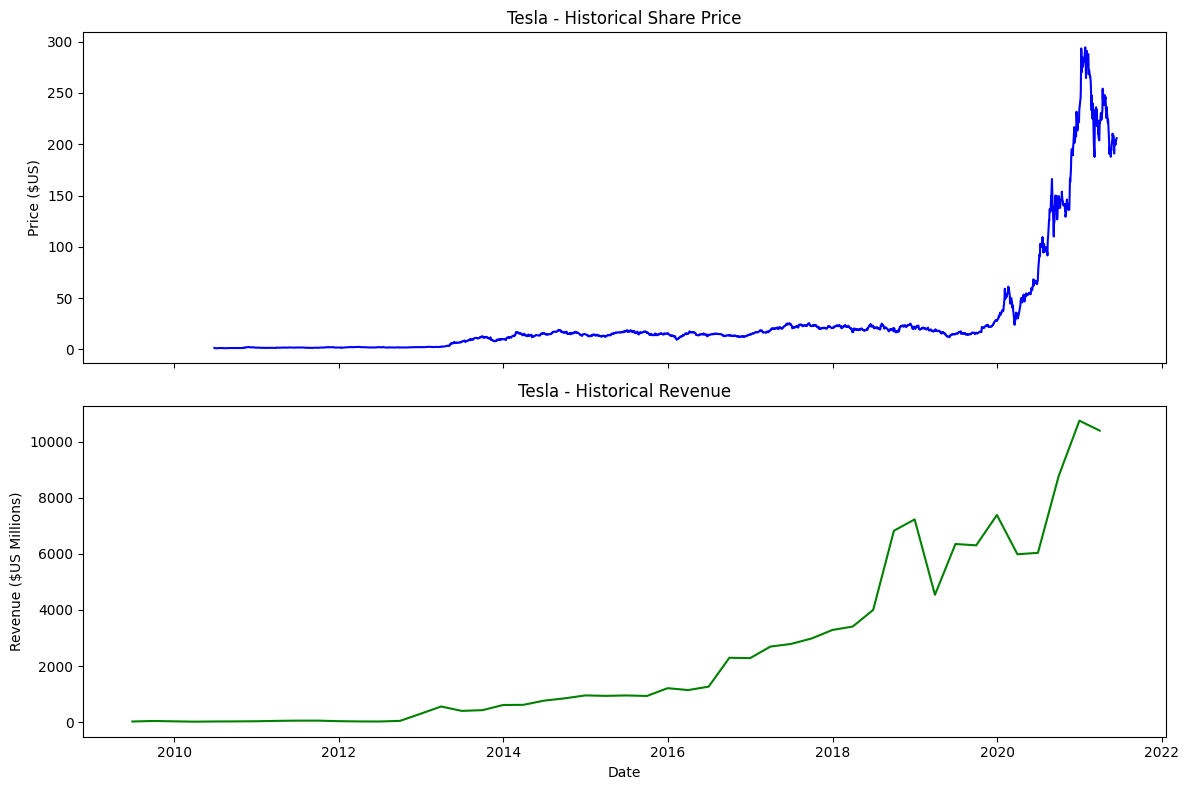

In [ ]:
make_graph(tlsa_data, tesla_revenue, 'Tesla')


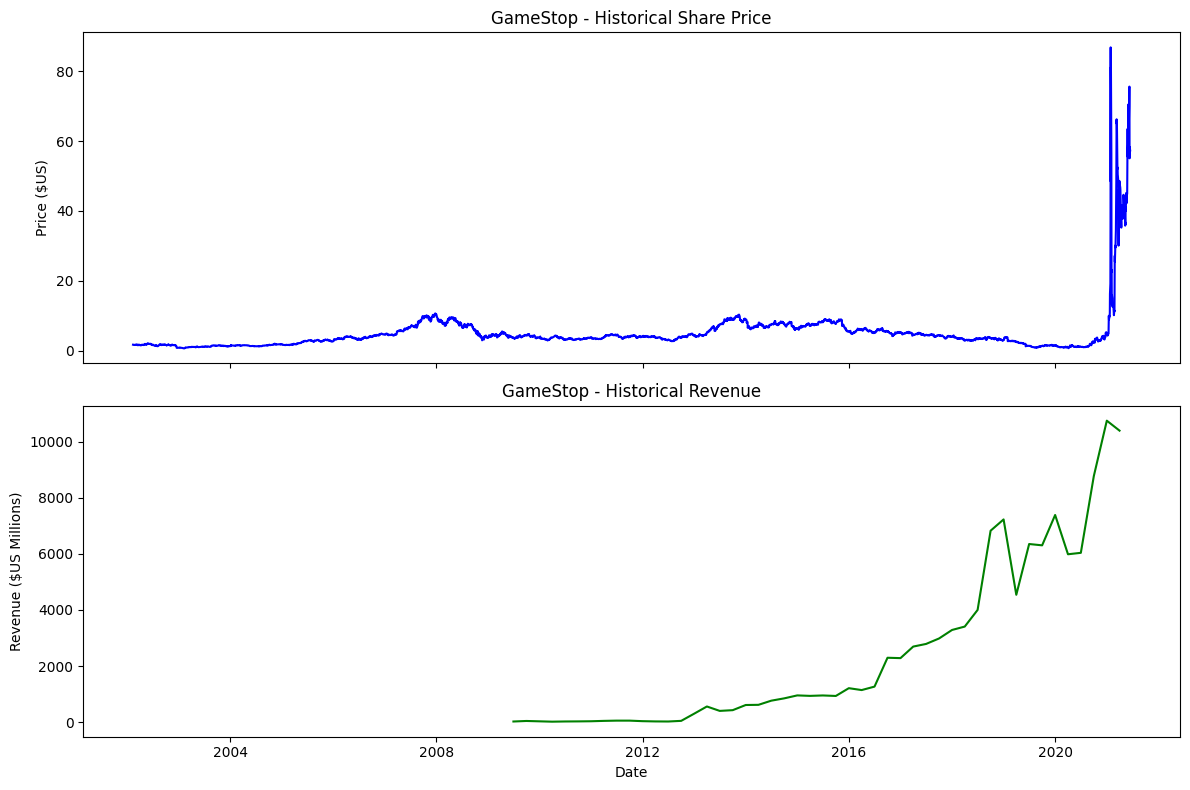

In [ ]:
make_graph(gme_data, gme_revenue, 'GameStop')